# Session 1: Fine-tuning a Transformer with Hugging Face

**Goal of today:** take a pre-trained model (DistilBERT) that knows English but knows nothing about our task, and teach it to classify movie reviews as POSITIVE or NEGATIVE.

We will do it two ways:

1. **Full fine-tuning** - update all ~67 million weights.
2. **LoRA (Parameter-Efficient Fine-Tuning)** - freeze the model, train ~1% extra weights.

Then we compare them on accuracy, time, GPU memory and disk size.

**Before you start (Colab):** `Runtime -> Change runtime type -> T4 GPU`. Fine-tuning on CPU will take hours.

**Flow of the notebook**

| Part | What we do |
|---|---|
| 1 | Setup and version check |
| 2 | Load and inspect the dataset |
| 3 | Tokenizer: what the model actually sees |
| 4 | Model: what is inside, what is new |
| 5 | One forward pass by hand (under the hood) |
| 6 | Full fine-tuning with `Trainer` |
| 7 | Evaluate and look at the mistakes |
| 8 | Save, reload, and use with `pipeline` |
| 9 | LoRA fine-tuning |
| 10 | Compare both approaches |
| 11 | Exercises |

**Student copy:** cells marked `TODO` are written together in class. The complete notebook is shared after the session.

## Part 1: Setup

We pin exact library versions. Hugging Face libraries change fast, and many online tutorials break because an argument got renamed (you will see two such renames today). Pinning means this notebook behaves the same next month.

We do **not** pin `torch` - Colab already has a GPU build of it installed.

In [ ]:
!pip install -q transformers==5.19.0 datasets==5.1.0 peft==0.21.2 accelerate==1.15.0 scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 40.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 24.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 14.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [1]:
import pyarrow
pyarrow.__version__

'23.0.1'

Imports and a quick check: library versions and whether a GPU is visible.
If `GPU unavailable` prints `False`, change the runtime type before going further.

In [17]:
import os
import gc
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

import transformers
import datasets
import peft

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    pipeline,
    set_seed,
)
from peft import LoraConfig, get_peft_model, TaskType, PeftModel
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

print("transformers :", transformers.__version__)
print("datasets     :", datasets.__version__)
print("peft         :", peft.__version__)
print("torch        :", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name     :", torch.cuda.get_device_name(0))

# same random numbers every run -> results are comparable between runs
set_seed(42)

transformers : 5.18.0
datasets     : 4.8.5
peft         : 0.21.1
torch        : 2.11.0+cu130
GPU available: True
GPU name     : Tesla T4


A small helper we will reuse: total size of a folder on disk in MB. We use it later to compare the saved full model vs the saved LoRA adapter.

In [18]:
def folder_size_mb(path):
    total = 0
    for root, _, files in os.walk(path):
        for f in files:
            total += os.path.getsize(os.path.join(root, f))
    return round(total / (1024 * 1024), 2)

## Part 2: Load and inspect the dataset

**IMDB** - 50,000 movie reviews, each labelled `0` (negative) or `1` (positive). 25k for training, 25k for testing.

`load_dataset` downloads it from the Hugging Face Hub and caches it, so the second run is instant.

In [19]:
raw = load_dataset("stanfordnlp/imdb")
raw

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

A `DatasetDict` is like a Python dict of tables: `train`, `test` (and `unsupervised`, which has no labels - we ignore it).

Let us look at what the label column really is, and at one row.

In [20]:
print(raw["train"].features)
print()

label_names = raw["train"].features["label"].names
print("label names:", label_names)

sample = raw["train"][0]
print("label:", sample["label"], "->", label_names[sample["label"]])
print("text :", sample["text"][:500], "...")

{'text': Value('string'), 'label': ClassLabel(names=['neg', 'pos'])}

label names: ['neg', 'pos']
label: 0 -> neg
text : I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attent ...


In [21]:
unsup = raw['unsupervised']
print(unsup['text'][0])
print(unsup['label'][0])

This is just a precious little diamond. The play, the script are excellent. I cant compare this movie with anything else, maybe except the movie "Leon" wonderfully played by Jean Reno and Natalie Portman. But... What can I say about this one? This is the best movie Anne Parillaud has ever played in (See please "Frankie Starlight", she's speaking English there) to see what I mean. The story of young punk girl Nikita, taken into the depraved world of the secret government forces has been exceptionally over used by Americans. Never mind the "Point of no return" and especially the "La femme Nikita" TV series. They cannot compare the original believe me! Trash these videos. Buy this one, do not rent it, BUY it. BTW beware of the subtitles of the LA company which "translate" the US release. What a disgrace! If you cant understand French, get a dubbed version. But you'll regret later :)
-1


In [22]:
import seaborn as sns

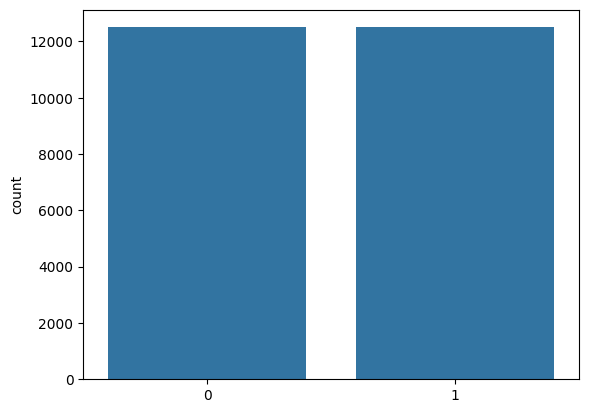

In [23]:
sns.countplot(x = raw["train"]['label']);

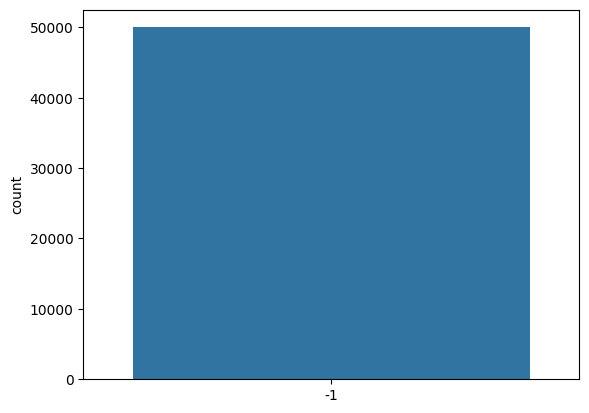

In [24]:
import seaborn as sns
sns.countplot(x = unsup['label']);
# this is unlabelled data

**Why a subset?** Training on all 25k reviews takes ~25 minutes on a T4. For class we use 4,000 training and 1,000 test reviews - enough to get ~88% accuracy in a few minutes.

`shuffle` first is important: the IMDB train split is **sorted by label** (all negatives, then all positives). Taking the first 4,000 rows without shuffling would give us only negative reviews.

In [25]:
train_raw = raw["train"].shuffle(seed=42).select(range(4000))
test_raw = raw["test"].shuffle(seed=42).select(range(1000))

# proof of the sorting problem: first 4000 rows without shuffling
print("unshuffled first 4000 labels:", pd.Series(raw["train"][:4000]["label"]).value_counts().to_dict())

# after shuffling, both classes are present in a balanced way
print("train label counts:", pd.Series(train_raw["label"]).value_counts().to_dict())
print("test  label counts:", pd.Series(test_raw["label"]).value_counts().to_dict())

unshuffled first 4000 labels: {0: 4000}
train label counts: {0: 2015, 1: 1985}
test  label counts: {0: 512, 1: 488}


How long are the reviews? This matters because the model has a maximum input length (512 tokens for DistilBERT). Here we count words; next part we count tokens.

count    4000.0
mean      230.1
std       169.1
min        12.0
25%       126.0
50%       173.0
75%       279.2
max      1601.0
dtype: float64


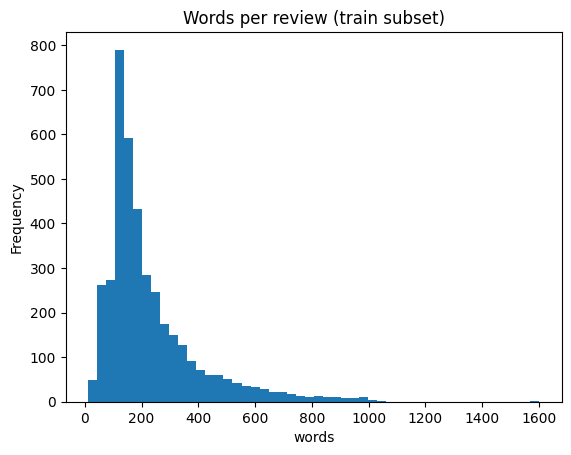

In [26]:
word_counts = pd.Series([len(t.split()) for t in train_raw["text"]])
print(word_counts.describe().round(1))

word_counts.plot.hist(bins=50, title="Words per review (train subset)")
plt.xlabel("words")
plt.show()

## Part 3: The tokenizer - what the model actually sees

A model cannot read text. It reads **numbers**. The tokenizer:

1. splits text into tokens (words or word-pieces),
2. maps each token to an ID from a fixed vocabulary,
3. adds special tokens the model was trained with (`[CLS]` at the start, `[SEP]` at the end),
4. builds an `attention_mask` (1 = real token, 0 = padding).

**Rule:** always load the tokenizer with the *same name* as the model. A different tokenizer = different IDs = garbage input.

In [27]:
MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print(type(tokenizer).__name__)
print("vocabulary size:", tokenizer.vocab_size)
print("max length     :", tokenizer.model_max_length)
print("special tokens :", tokenizer.all_special_tokens)

BertTokenizer
vocabulary size: 30522
max length     : 512
special tokens : ['[UNK]', '[SEP]', '[PAD]', '[CLS]', '[MASK]']


Tokenize one sentence and look at every piece.

Notice:
- `uncased` model -> everything is lower-cased.
- Rare words get split into pieces; continuation pieces start with `##`.
- `[CLS]` (id 101) and `[SEP]` (id 102) are added automatically.

In [28]:
text = "The movie was unbelievably boring!"
enc = tokenizer(text)

print("input_ids     :", enc["input_ids"])
print("attention_mask:", enc["attention_mask"])
print("tokens        :", tokenizer.convert_ids_to_tokens(enc["input_ids"]))
print("decoded back  :", tokenizer.decode(enc["input_ids"]))

input_ids     : [101, 1996, 3185, 2001, 4895, 8671, 2666, 3567, 6321, 11771, 999, 102]
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
tokens        : ['[CLS]', 'the', 'movie', 'was', 'un', '##bel', '##ie', '##va', '##bly', 'boring', '!', '[SEP]']
decoded back  : [CLS] the movie was unbelievably boring! [SEP]


In [29]:
text1 = ["the movie was so good that i fell asleep",
         "The movie was unbelievably boring!"]
enc = tokenizer(text1, padding = True)

print("input_ids     :", enc["input_ids"])
print("attention_mask:", enc["attention_mask"])
# print("tokens        :", tokenizer.convert_ids_to_tokens(enc["input_ids"]))
print("decoded back  :", tokenizer.decode(enc["input_ids"]))

input_ids     : [[101, 1996, 3185, 2001, 2061, 2204, 2008, 1045, 3062, 6680, 102, 0], [101, 1996, 3185, 2001, 4895, 8671, 2666, 3567, 6321, 11771, 999, 102]]
attention_mask: [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0], [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]
decoded back  : ['[CLS] the movie was so good that i fell asleep [SEP] [PAD]', '[CLS] the movie was unbelievably boring! [SEP]']


Now count **tokens** (not words) for the training reviews. Tokens are always more than words, because of word-pieces and punctuation.

We use this to choose `max_length`. Anything longer gets truncated (cut). Longer `max_length` = more GPU memory and slower training, so we pick a value that covers most reviews without being wasteful.

**Library-change trap #0:** in `datasets` 5.x, `train_raw["text"]` is a lazy *Column* object, not a Python list. The tokenizer only accepts `str` or `list[str]`, so we wrap it in `list(...)`. Old tutorials skip this and fail with a `ValueError`.

In [30]:
print(type(train_raw["text"]).__name__)   # Column, not list

token_counts = pd.Series([len(ids) for ids in tokenizer(list(train_raw["text"]))["input_ids"]])
print(token_counts.describe().round(1))

for limit in [128, 256, 384, 400, 512]:
    covered = (token_counts <= limit).mean() * 100
    print(f"max_length={limit}: {covered:.1f}% of reviews fit without cutting")

Column


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (936 > 512). Running this sequence through the model will result in indexing errors


count    4000.0
mean      309.1
std       227.2
min        17.0
25%       167.0
50%       230.0
75%       377.0
max      2315.0
dtype: float64
max_length=128: 11.2% of reviews fit without cutting
max_length=256: 56.4% of reviews fit without cutting
max_length=384: 75.9% of reviews fit without cutting
max_length=400: 77.5% of reviews fit without cutting
max_length=512: 86.0% of reviews fit without cutting


We pick **256**. Around half the reviews fit fully (check the printed numbers), and for the longer ones the first 256 tokens usually already make the sentiment clear. 512 would be more accurate but roughly 2-3x slower.

Now tokenize the whole subset with `.map(batched=True)` - this sends 1,000 rows at a time to the tokenizer, which is much faster than one by one.

Note: we do **not** pad here. Padding happens later, per batch (see the data collator).

In [31]:
MAX_LENGTH = 256

def tokenize(batch):
    # TODO: call the tokenizer on batch["text"]
    #       - cut long reviews at MAX_LENGTH (truncation)
    #       - do NOT pad here

    return tokenizer(batch["text"], truncation=True,
                     max_length= MAX_LENGTH)

train_tok = train_raw.map(tokenize, batched=True, remove_columns=["text"])
test_tok = test_raw.map(tokenize, batched=True, remove_columns=["text"])

print(train_tok)
print("lengths of first 5 rows:", [len(x) for x in train_tok[:5]["input_ids"]])

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 4000
})
lengths of first 5 rows: [179, 159, 237, 163, 256]


**Dynamic padding with a data collator.**

A GPU needs every row in a batch to have the same length. Two options:
- pad *everything* to 256 up front -> lots of wasted zeros for short reviews;
- pad *each batch* only up to its longest row -> what `DataCollatorWithPadding` does.

Below: three rows of different lengths become one tensor, padded to the longest of the three. Look at the zeros in `attention_mask`.

In [32]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

rows = [train_tok[i] for i in range(3)]
print("individual lengths:", [len(r["input_ids"]) for r in rows])

batch = data_collator(rows)
print("batch keys        :", list(batch.keys()))
print("input_ids shape   :", tuple(batch["input_ids"].shape))
print("attention_mask row lengths (real tokens):", batch["attention_mask"].sum(dim=1).tolist())
print("label tensor      :", batch["labels"])

individual lengths: [179, 159, 237]
batch keys        : ['input_ids', 'token_type_ids', 'attention_mask', 'labels']
input_ids shape   : (3, 237)
attention_mask row lengths (real tokens): [179, 159, 237]
label tensor      : tensor([1, 1, 0])


One detail: our column is called `label`, but the batch key is `labels` (plural). The collator renames it, because the model's `forward()` expects `labels`. If you ever see an error about a missing `labels` argument, this is the first place to look.

## Part 4: The model - what is inside, what is new

`AutoModelForSequenceClassification` = pre-trained DistilBERT body **+ a brand-new classification head** on top.

- The body already understands language (trained on Wikipedia + books).
- The head is a small linear layer that maps the sentence representation to our 2 labels. It starts with **random weights**.

You will see a message saying some weights were *newly initialized*. That is expected - it is the head. It is exactly what we are about to train.

`id2label` / `label2id` store readable label names inside the model, so later predictions say `POSITIVE` instead of `LABEL_1`.

In [33]:
id2label = {0: "NEGATIVE", 1: "POSITIVE"}
label2id = {"NEGATIVE": 0, "POSITIVE": 1}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=id2label,
    label2id=label2id,
)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Let us look inside: top-level blocks, total parameters, and the new head.

In [34]:
for name, module in model.named_children():
    n_params = sum(p.numel() for p in module.parameters())
    print(f"{name:15s} {type(module).__name__:25s} {n_params:>12,} params")

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\ntotal params    : {total_params:,}")
print(f"trainable params: {trainable_params:,}  (full fine-tuning trains everything)")

print("\nthe new head:")
print(model.pre_classifier)
print(model.classifier)

distilbert      DistilBertModel             66,362,880 params
pre_classifier  Linear                         590,592 params
classifier      Linear                           1,538 params
dropout         Dropout                              0 params

total params    : 66,955,010
trainable params: 66,955,010  (full fine-tuning trains everything)

the new head:
Linear(in_features=768, out_features=768, bias=True)
Linear(in_features=768, out_features=2, bias=True)


## Part 5: One forward pass by hand (under the hood)

Before using `Trainer`, let us do what it does internally for **one** batch:

1. send the batch through the model,
2. get **logits** (raw scores, one per class),
3. turn logits into probabilities with softmax,
4. compute the **loss** (cross-entropy) against the true labels.

`Trainer` repeats this thousands of times and, after each batch, adjusts the weights to reduce the loss (backpropagation + optimizer step).

In [35]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

batch = data_collator([train_tok[i] for i in range(4)])
batch = {k: v.to(device) for k, v in batch.items()}

model.eval()
with torch.no_grad():
    out = model(**batch)

print("logits shape:", tuple(out.logits.shape), "-> (batch size, number of classes)")
print("logits      :", out.logits.cpu().numpy().round(3))
print("probs       :", torch.softmax(out.logits, dim=-1).cpu().numpy().round(3))
print("true labels :", batch["labels"].tolist())
print("model loss  :", round(out.loss.item(), 4))

# the same loss, computed ourselves -> proves what the model does internally
manual_loss = F.cross_entropy(out.logits, batch["labels"])
print("manual loss :", round(manual_loss.item(), 4))

logits shape: (4, 2) -> (batch size, number of classes)
logits      : [[-0.069 -0.028]
 [-0.053 -0.005]
 [-0.029 -0.043]
 [ 0.005 -0.   ]]
probs       : [[0.49  0.51 ]
 [0.488 0.512]
 [0.504 0.496]
 [0.501 0.499]]
true labels : [1, 1, 0, 1]
model loss  : 0.6809
manual loss : 0.6809


Probabilities are close to 0.5/0.5 and the loss is close to **0.693** (= ln 2). That is the loss of a model that is just guessing between 2 classes - which makes sense, the head is random.

After training we expect confident probabilities and a much lower loss.

## Part 6: Full fine-tuning with `Trainer`

### 6.1 Metrics

`Trainer` gives us the loss automatically. For humans, accuracy and F1 are easier to read. `compute_metrics` receives the logits and true labels for the whole eval set and returns a dict.

In [36]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1": f1_score(labels, preds),
    }

### 6.2 Training arguments

| Argument | Value | Meaning |
|---|---|---|
| `num_train_epochs` | 2 | passes over the training data |
| `per_device_train_batch_size` | 16 | reviews per weight update |
| `learning_rate` | 2e-5 | small step size; large values destroy the pre-trained knowledge |
| `weight_decay` | 0.01 | mild regularisation against overfitting |
| `eval_strategy` | "epoch" | evaluate on the test set after every epoch |
| `save_strategy` | "epoch" | save a checkpoint after every epoch |
| `load_best_model_at_end` | True | keep the checkpoint with the best `metric_for_best_model` |
| `fp16` | True on GPU | half-precision math: faster and uses less memory on a T4 |
| `report_to` | "none" | do not try to log to Weights & Biases |

**Library-change trap #1:** older tutorials write `evaluation_strategy=`. It was renamed to `eval_strategy`; the old name now raises an error.

In [37]:
# TODO: create TrainingArguments using the table above
#       output_dir="checkpoints_full", 2 epochs, batch size 16 (eval 32),
#       learning rate 2e-5, weight decay 0.01, evaluate + save every epoch,
#       keep the best model by "f1", log every 25 steps,
#       fp16 only if a GPU is available, report_to="none", seed 42
full_args = TrainingArguments(
    output_dir="checkpoints_full",
    num_train_epochs=5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    logging_steps=25,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42
)

### 6.3 The Trainer

`Trainer` wires everything together: model, arguments, data, collator, metrics.

**Library-change trap #2:** older tutorials pass `tokenizer=tokenizer`. In current versions this argument is `processing_class=tokenizer` (it can also be an image processor, hence the general name).

We evaluate **before** training to get a baseline - expect ~50% accuracy (random guessing).

In [38]:
# TODO: create the Trainer with model, args, train/eval datasets,
#       processing_class, data_collator and compute_metrics
full_trainer = Trainer(
    model = model,
    args = full_args,
    train_dataset = train_tok,
    eval_dataset = test_tok,
    processing_class = tokenizer,
    data_collator = data_collator,
    compute_metrics = compute_metrics
)

baseline = full_trainer.evaluate()
print({k: round(v, 4) for k, v in baseline.items() if k in ["eval_loss", "eval_accuracy", "eval_f1"]})

Training Loss,Validation Loss,Epoch,Accuracy,F1
No log,0.696718,0,0.408000,0.442561


{'eval_loss': 0.6967, 'eval_accuracy': 0.408, 'eval_f1': 0.4426}


### 6.4 Train

We also record wall-clock time and peak GPU memory, so we can compare with LoRA later. On a T4 this takes roughly 4-6 minutes.

In [39]:
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

start = time.time()
full_trainer.train()
full_time = time.time() - start

full_peak_mem = torch.cuda.max_memory_allocated() / 1024**3 if torch.cuda.is_available() else float("nan")
print(f"training time : {full_time / 60:.1f} min")
print(f"peak GPU mem  : {full_peak_mem:.2f} GB")

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.384706,0.286711,0.875000,0.875622
2,0.190372,0.326978,0.878000,0.882012
3,0.137984,0.360518,0.880000,0.877049
4,0.068603,0.493592,0.882000,0.882470
5,0.021064,0.530746,0.876000,0.876740


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

training time : 3.7 min
peak GPU mem  : 1.68 GB


### 6.5 Training curve

`trainer.state.log_history` is a list of every log entry (training loss every 25 steps, eval metrics every epoch). Plotting it is the quickest way to see if training worked:
- training loss should go **down**,
- eval loss going **up** while training loss goes down = overfitting.

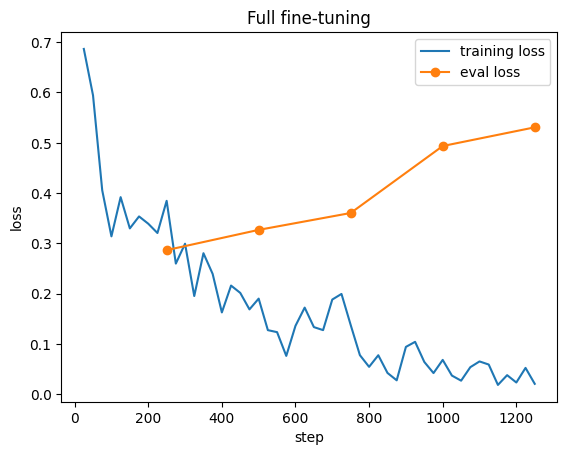

,epoch,eval_loss,eval_accuracy,eval_f1
10,1.0,0.2867,0.875,0.8756
21,2.0,0.3270,0.878,0.8820
32,3.0,0.3605,0.880,0.8770
43,4.0,0.4936,0.882,0.8825
54,5.0,0.5307,0.876,0.8767


In [40]:
history = pd.DataFrame(full_trainer.state.log_history)

train_curve = history.dropna(subset=["loss"])
eval_curve = history.dropna(subset=["eval_loss"])

plt.plot(train_curve["step"], train_curve["loss"], label="training loss")
plt.plot(eval_curve["step"], eval_curve["eval_loss"], "o-", label="eval loss")
plt.xlabel("step")
plt.ylabel("loss")
plt.title("Full fine-tuning")
plt.legend()
plt.show()

eval_curve[["epoch", "eval_loss", "eval_accuracy", "eval_f1"]].round(4)

## Part 7: Evaluate and look at the mistakes

Accuracy is one number. A confusion matrix shows **which** mistakes the model makes, and reading actual wrong predictions tells you **why**.

Training Loss,Validation Loss,Epoch,Accuracy,F1
0.021064,0.493592,5,0.882000,0.882470


{'eval_loss': 0.4936, 'eval_accuracy': 0.882, 'eval_f1': 0.8825}



              precision    recall  f1-score   support

    NEGATIVE      0.907     0.857     0.882       512
    POSITIVE      0.859     0.908     0.882       488

    accuracy                          0.882      1000
   macro avg      0.883     0.883     0.882      1000
weighted avg      0.883     0.882     0.882      1000



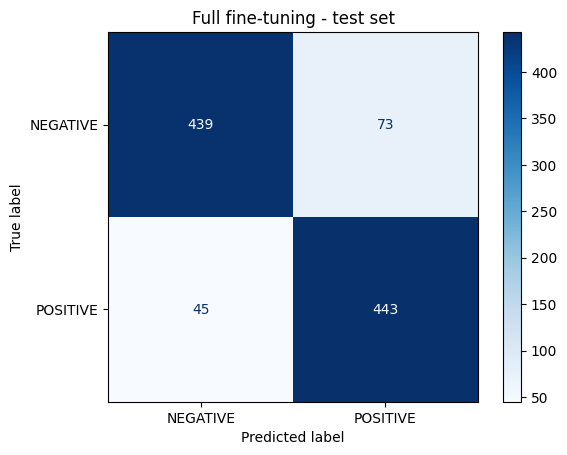

In [41]:
full_metrics = full_trainer.evaluate()
print({k: round(v, 4) for k, v in full_metrics.items() if k in ["eval_loss", "eval_accuracy", "eval_f1"]})

pred_output = full_trainer.predict(test_tok)
preds = np.argmax(pred_output.predictions, axis=-1)
labels = pred_output.label_ids

print()
print(classification_report(labels, preds, target_names=["NEGATIVE", "POSITIVE"], digits=3))

ConfusionMatrixDisplay.from_predictions(labels, preds, display_labels=["NEGATIVE", "POSITIVE"], cmap="Blues")
plt.title("Full fine-tuning - test set")
plt.show()

Now the interesting part: reviews the model got wrong, with its confidence. Typical reasons: sarcasm, mixed reviews ("great acting, terrible story"), or the sentiment appears only after the 256-token cut.

In [42]:
probs = torch.softmax(torch.tensor(pred_output.predictions), dim=-1).numpy()
wrong = np.where(preds != labels)[0]
print(f"{len(wrong)} wrong out of {len(labels)}\n")

for i in wrong[:5]:
    print(f"true: {id2label[labels[i]]:8s} | predicted: {id2label[preds[i]]:8s} | confidence: {probs[i].max():.2f}")
    print(test_raw[int(i)]["text"][:400], "...")
    print("-" * 80)

118 wrong out of 1000

true: NEGATIVE | predicted: POSITIVE | confidence: 0.78
These days, writers, directors and producers are relying more and more on the "surprise" ending. The old art of bringing a movie to closure, taking all of the information we have learned through out the movie and bringing it to a nice complete ending, has been lost. Now what we have is a movie that, no matter how complex, detailed, or frivolous, can be wrapped up in 5 minutes. It was all in his/he ...
--------------------------------------------------------------------------------
true: NEGATIVE | predicted: POSITIVE | confidence: 0.99
Coming from Kiarostami, this art-house visual and sound exposition is a surprise. For a director known for his narratives and keen observation of humans, especially children, this excursion into minimalist cinematography begs for questions: Why did he do it? Was it to keep him busy during a vacation at the shore? <br /><br />"Five, 5 Long Takes" consists of, you guessed it, fi

## Part 8: Save, reload, and use with `pipeline`

`save_model` writes the weights (`model.safetensors`) and config; saving the tokenizer next to it makes the folder self-contained - anyone can load it with one line.

In [43]:
FULL_DIR = "imdb-distilbert-full"
full_trainer.save_model(FULL_DIR)
tokenizer.save_pretrained(FULL_DIR)

print(sorted(os.listdir(FULL_DIR)))
print("size on disk:", folder_size_mb(FULL_DIR), "MB")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']
size on disk: 256.11 MB


Reload from the folder with `pipeline` - the same `pipeline` you used with ready-made models, now pointing at **your** model. `top_k=None` returns the score for every label.

Try a few tricky sentences: negation, sarcasm, mixed opinion.

In [44]:
classifier = pipeline("text-classification", model=FULL_DIR, top_k=None, device=0 if torch.cuda.is_available() else -1)

reviews = [
    "An absolute masterpiece. I would watch it again tomorrow.",
    "Two hours of my life I will never get back.",
    "Not bad at all, actually quite enjoyable.",
    "Oh great, another superhero movie. Just what the world needed.",
    "The acting was brilliant but the story made no sense.",
]

for r, scores in zip(reviews, classifier(reviews)):
    best = max(scores, key=lambda s: s["score"])
    print(f"{best['label']:8s} {best['score']:.3f} | {r}")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

POSITIVE 0.996 | An absolute masterpiece. I would watch it again tomorrow.
POSITIVE 0.925 | Two hours of my life I will never get back.
NEGATIVE 0.595 | Not bad at all, actually quite enjoyable.
POSITIVE 0.977 | Oh great, another superhero movie. Just what the world needed.
NEGATIVE 0.996 | The acting was brilliant but the story made no sense.


**What `pipeline` does under the hood** = tokenizer -> model -> softmax -> map index to label name. Same three steps by hand:

In [45]:
loaded_model = AutoModelForSequenceClassification.from_pretrained(FULL_DIR).to(device).eval()

inputs = tokenizer(reviews[0], return_tensors="pt", truncation=True, max_length=MAX_LENGTH).to(device)
with torch.no_grad():
    logits = loaded_model(**inputs).logits

# TODO: convert logits to probabilities, pick the best index,
#       and print its label name using loaded_model.config.id2label

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

## Part 9: LoRA - fine-tuning by training only ~1% of the weights

**The problem:** full fine-tuning updates every weight. For DistilBERT (67M) that is fine. For a 7-billion-parameter LLM it needs multiple large GPUs, and every fine-tuned version is another 14 GB file.

**The LoRA idea:**
- **Freeze** the original weight matrix `W` (it is never changed).
- Next to it, add two small matrices `A` and `B`. Their product `B x A` is the *change* we want: `W_new = W + B x A`.
- For a 768 x 768 matrix (590k numbers), with rank `r = 8`: `A` is 8 x 768 and `B` is 768 x 8 -> only ~12k numbers to train.

**Analogy:** instead of rewriting a 500-page book, you add sticky notes on a few pages. The book stays untouched; you can peel the notes off, or keep different sets of notes for different purposes.

First we free the GPU memory used by the full model.

In [46]:
del model, full_trainer, loaded_model, classifier
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"GPU memory in use now: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

GPU memory in use now: 1.29 GB


Load a **fresh** pre-trained model (not the one we just trained) and wrap it with LoRA.

| Argument | Value | Meaning |
|---|---|---|
| `task_type` | `SEQ_CLS` | tells PEFT this is sequence classification, so it also keeps the new head trainable |
| `r` | 8 | rank = size of the small matrices; higher = more capacity, more params |
| `lora_alpha` | 16 | scaling of the LoRA update (common rule: 2 x r) |
| `lora_dropout` | 0.1 | dropout on the LoRA path |
| `target_modules` | `["q_lin", "v_lin"]` | which layers get LoRA - DistilBERT names its query/value projections `q_lin`, `v_lin` |

`target_modules` names differ per model family (BERT: `query`, `value`; Llama: `q_proj`, `v_proj`). `print(model)` shows the names.

In [12]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [47]:
base_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, id2label=id2label, label2id=label2id
)

# TODO: create a LoraConfig using the table above,
#       then wrap base_model with get_peft_model

lora_config = LoraConfig(
    task_type="SEQ_CLS",
    r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules=["q_lin", "v_lin"],
)

lora_model = get_peft_model(base_model, lora_config)

lora_model.print_trainable_parameters()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 739,586 || all params: 67,694,596 || trainable%: 1.0925


Under the hood: what did PEFT change? One attention layer before and after - the original `Linear` is now `base_layer`, with `lora_A` and `lora_B` next to it.

In [48]:
print(lora_model.base_model.model.distilbert.transformer.layer[0].attention.q_lin)

lora.Linear(
  (base_layer): Linear(in_features=768, out_features=768, bias=True)
  (lora_dropout): ModuleDict(
    (default): Dropout(p=0.1, inplace=False)
  )
  (lora_A): ModuleDict(
    (default): Linear(in_features=768, out_features=8, bias=False)
  )
  (lora_B): ModuleDict(
    (default): Linear(in_features=8, out_features=768, bias=False)
  )
  (lora_embedding_A): ParameterDict()
  (lora_embedding_B): ParameterDict()
  (lora_magnitude_vector): ModuleDict()
)


Which parameters are trainable now? Group them by type. Expect LoRA `A`/`B` matrices in 6 layers x 2 targets, plus the classification head.

In [49]:
groups = {}
for name, p in lora_model.named_parameters():
    if not p.requires_grad:
        continue
    if "lora_" in name:
        key = "LoRA A/B matrices"
    elif "classifier" in name:
        key = "classification head"
    else:
        key = "other"
    groups[key] = groups.get(key, 0) + p.numel()

for k, v in groups.items():
    print(f"{k:22s} {v:>10,}")

LoRA A/B matrices         147,456
classification head       592,130


Train with the same data and epochs. One change: **learning rate 2e-4** (10x higher). LoRA trains far fewer weights, starting from zero, so it needs bigger steps.

We skip saving checkpoints here to keep the run short.

In [50]:
lora_args = TrainingArguments(
    output_dir="checkpoints_lora",
    num_train_epochs=15,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=25,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42,
)

lora_trainer = Trainer(
    model=lora_model,
    args=lora_args,
    train_dataset=train_tok,
    eval_dataset=test_tok,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

start = time.time()
lora_trainer.train()
lora_time = time.time() - start

lora_peak_mem = torch.cuda.max_memory_allocated() / 1024**3 if torch.cuda.is_available() else float("nan")
lora_metrics = lora_trainer.evaluate()

print(f"training time : {lora_time / 60:.1f} min")
print(f"peak GPU mem  : {lora_peak_mem:.2f} GB")
print({k: round(v, 4) for k, v in lora_metrics.items() if k in ["eval_loss", "eval_accuracy", "eval_f1"]})

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.562306,0.512026,0.825000,0.808743
2,0.364238,0.351810,0.841000,0.834202
3,0.375238,0.339733,0.846000,0.840580
4,0.335248,0.334165,0.857000,0.853933
5,0.329213,0.330240,0.860000,0.858586
6,0.320669,0.331756,0.858000,0.858566
7,0.363398,0.321153,0.859000,0.856269
8,0.301808,0.318009,0.861000,0.859169
9,0.268826,0.320572,0.858000,0.858283
10,0.257308,0.317136,0.859000,0.857143


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.280119,0.318281,15,0.860000,0.861386


training time : 6.0 min
peak GPU mem  : 2.25 GB
{'eval_loss': 0.3183, 'eval_accuracy': 0.86, 'eval_f1': 0.8614}


Save the LoRA adapter. Only the small trained part is saved - not the 67M frozen weights. Compare the size with the full model folder.

In [51]:
LORA_DIR = "imdb-distilbert-lora-adapter"
lora_model.save_pretrained(LORA_DIR)

print(sorted(os.listdir(LORA_DIR)))
print("adapter size   :", folder_size_mb(LORA_DIR), "MB")
print("full model size:", folder_size_mb(FULL_DIR), "MB")

['README.md', 'adapter_config.json', 'adapter_model.safetensors']
adapter size   : 2.83 MB
full model size: 256.11 MB


To use the adapter later: load the original base model, attach the adapter, and optionally **merge** it into the base weights (`W + B x A` computed once). A merged model is a normal transformers model - no PEFT needed at inference and no extra latency.

In [52]:
fresh_base = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, id2label=id2label, label2id=label2id
)
with_adapter = PeftModel.from_pretrained(fresh_base, LORA_DIR)
merged_model = with_adapter.merge_and_unload()
print("merged model type:", type(merged_model).__name__)

lora_classifier = pipeline(
    "text-classification", model=merged_model, tokenizer=tokenizer,
    device=0 if torch.cuda.is_available() else -1,
)
for r, res in zip(reviews, lora_classifier(reviews)):
    print(f"{res['label']:8s} {res['score']:.3f} | {r}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


merged model type: DistilBertForSequenceClassification
POSITIVE 0.972 | An absolute masterpiece. I would watch it again tomorrow.
POSITIVE 0.594 | Two hours of my life I will never get back.
NEGATIVE 0.776 | Not bad at all, actually quite enjoyable.
POSITIVE 0.766 | Oh great, another superhero movie. Just what the world needed.
NEGATIVE 0.883 | The acting was brilliant but the story made no sense.


## Part 10: Full fine-tuning vs LoRA

In [53]:
comparison = pd.DataFrame([
    {
        "method": "Full fine-tuning",
        "trainable params": f"{total_params:,}",
        "train time (min)": round(full_time / 60, 1),
        "peak GPU mem (GB)": round(full_peak_mem, 2),
        "accuracy": round(full_metrics["eval_accuracy"], 4),
        "f1": round(full_metrics["eval_f1"], 4),
        "saved size (MB)": folder_size_mb(FULL_DIR),
    },
    {
        "method": "LoRA (r=8)",
        "trainable params": f"{sum(groups.values()):,}",
        "train time (min)": round(lora_time / 60, 1),
        "peak GPU mem (GB)": round(lora_peak_mem, 2),
        "accuracy": round(lora_metrics["eval_accuracy"], 4),
        "f1": round(lora_metrics["eval_f1"], 4),
        "saved size (MB)": folder_size_mb(LORA_DIR),
    },
])
comparison

,method,trainable params,train time (min),peak GPU mem (GB),accuracy,f1,saved size (MB)
0,Full fine-tuning,"66,955,010",3.7,1.68,0.882,0.8825,256.11
1,LoRA (r=8),"739,586",6.0,2.25,0.860,0.8614,2.83


**How to read this**

- Accuracy: LoRA usually lands within 1-3 points of full fine-tuning.
- Saved size: the biggest difference. One base model + many small adapters (one per task or client) instead of many full copies.
- Time and memory: savings exist but are modest on a small model like DistilBERT, because the forward pass still goes through all 67M frozen weights. On billion-parameter LLMs the memory saving is what makes fine-tuning possible on one GPU at all (and QLoRA - LoRA on a 4-bit quantized model - pushes this further).

**When to fine-tune at all?**

| Need | Usually the right tool |
|---|---|
| Model must know facts from your documents | RAG (Sessions 3-4) |
| Specific output format or behaviour | Prompting + structured output (Session 2) |
| Fixed label set, lots of labelled data, low cost per prediction | Fine-tune a small model (today) |
| Consistent style / domain language an LLM keeps missing | LoRA fine-tune an LLM |

Fine-tuning teaches **behaviour and patterns**, not reliable facts.

## Part 11: Exercises

1. **Easy** - Change `MAX_LENGTH` to 128 and retrain the full model. What happens to time and accuracy? Why?
2. **Medium** - Retrain LoRA with `r=2` and with `r=32`. Fill a small table: trainable params, accuracy, adapter size.
3. **Challenge** - Fine-tune on a different dataset: `fancyzhx/ag_news` (4 news categories: World, Sports, Business, Sci/Tech). What must change? (hint: `num_labels`, `id2label`, the label names, and the `f1_score` average)

**Optional - share your model on the Hugging Face Hub** (needs a free HF account and a write token):

```python
from huggingface_hub import notebook_login
notebook_login()
loaded = AutoModelForSequenceClassification.from_pretrained(FULL_DIR)
loaded.push_to_hub("your-username/imdb-distilbert-full")
tokenizer.push_to_hub("your-username/imdb-distilbert-full")
```